# 01 - Building blocks

The components the SNNs are assembled from, each tested in isolation:

1. Retina model: Difference-of-Gaussians (DoG) filter
2. Spike encoding: rate (Bernoulli) coding and latency (time-to-first-spike) coding as PyTorch tensors
3. Adaptive LIF neuron
4. Max pooling of spike maps
5. A convolutional LIF layer in PyTorch (prototype of the encoder in notebook 02)

The NumPy versions used by the final pipeline live in `snn_detection/` (`encoding.py`, `neurons.py`).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make the snn_detection package importable

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from snn_detection.data import load_mnist
from snn_detection.encoding import dog_filter
from snn_detection.neurons import AdaptiveLIF

x_train, y_train, x_test, y_test = load_mnist(normalize=False)
torch.manual_seed(0)
np.random.seed(0)

## 1. Retina: Difference-of-Gaussians filter

A narrow Gaussian (centre) minus a wide one (surround), keeping only positive values,
models ON-centre retinal ganglion cells. It acts as an edge detector.

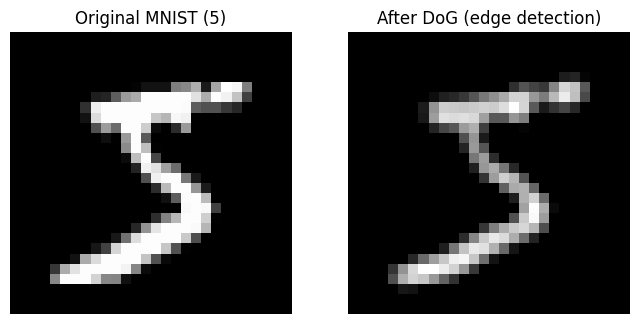

In [2]:
image, label = x_train[0], y_train[0]
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(image, cmap="gray"); axes[0].set_title(f"Original MNIST ({label})")
axes[1].imshow(dog_filter(image), cmap="gray"); axes[1].set_title("After DoG (edge detection)")
for ax in axes: ax.axis("off")
plt.show()

## 2. Spike encoding (tensor form)

Both encoders return a spike tensor of shape `[time, 1, H, W]`.

* **Rate coding**: every step each pixel fires with probability equal to its intensity in `[0, 1]`.
* **Latency coding**: each pixel fires once, at `round((1 - intensity) * (T - 1))`, so brighter pixels fire earlier. Pixels at or below `threshold` stay silent.

rate coding: 1639 spikes, latency coding: 145 spikes


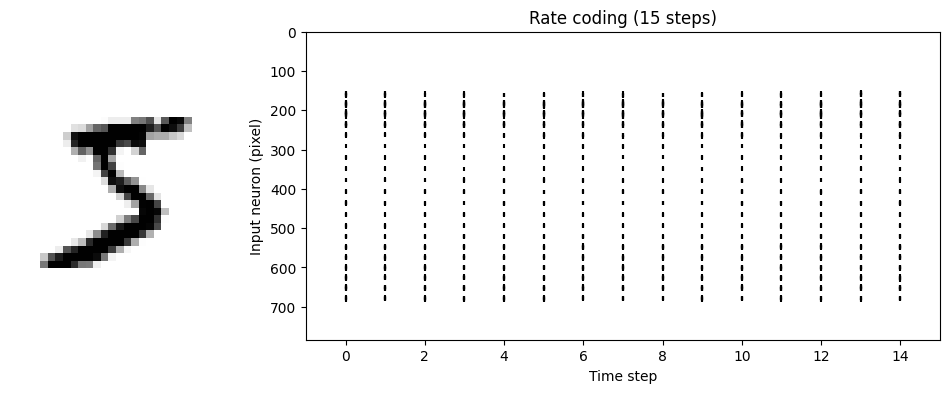

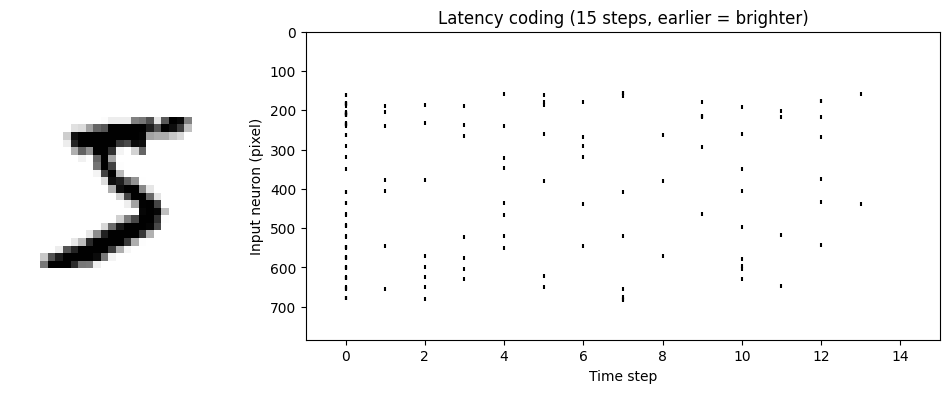

In [3]:
def rate_encode_torch(image, duration=15):
    image = torch.as_tensor(image).float()
    if image.max() > 1.0:
        image = image / 255.0
    return (torch.rand(duration, *image.shape) < image.clamp(0, 1)).float().unsqueeze(1)


def latency_encode_torch(image, duration=15, threshold=0.1):
    image = torch.as_tensor(image).float()
    if image.max() > 1.0:
        image = image / 255.0
    times = torch.round((1.0 - image) * (duration - 1)).long()
    spikes = torch.zeros(duration, 1, *image.shape)
    for t in range(duration):
        spikes[t, 0, (times == t) & (image > threshold)] = 1.0
    return spikes


def plot_raster(image, spike_tensor, title):
    t, _, r, c = torch.nonzero(spike_tensor).T.numpy()
    fig, (ax_img, ax_raster) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 3]})
    ax_img.imshow(image, cmap="gray_r"); ax_img.axis("off")
    ax_raster.scatter(t, r * 28 + c, s=10, color="black", marker="|")
    ax_raster.set(title=title, xlabel="Time step", ylabel="Input neuron (pixel)", ylim=(784, 0),
                  xlim=(-1, spike_tensor.shape[0]))
    plt.show()


rate_spikes = rate_encode_torch(image)
latency_spikes = latency_encode_torch(image)
print(f"rate coding: {int(rate_spikes.sum())} spikes, latency coding: {int(latency_spikes.sum())} spikes")
plot_raster(image, rate_spikes, "Rate coding (15 steps)")
plot_raster(image, latency_spikes, "Latency coding (15 steps, earlier = brighter)")

## 3. Adaptive LIF neuron

Under a constant input current the neuron fires repeatedly; each spike raises its
threshold (homeostasis), so the inter-spike interval grows.
`scripts/demo_lif_neuron.py` produces the full annotated plot.

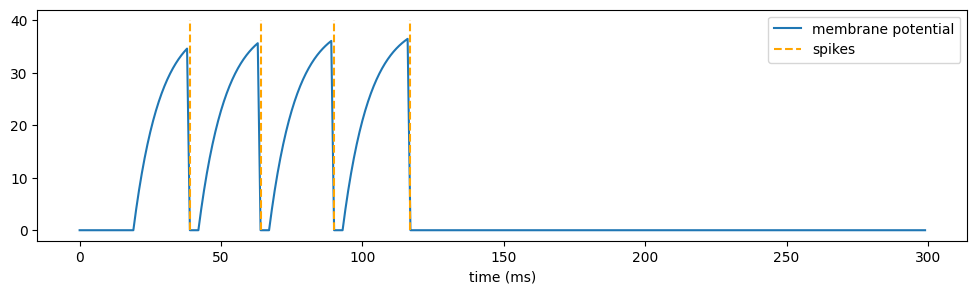

spike times: [39, 64, 90, 117]


In [4]:
neuron = AdaptiveLIF()
trace = [neuron.step(40.0 if 20 <= t < 120 else 0.0) for t in range(300)]
spikes = [t for t, (s, _) in enumerate(trace) if s]
plt.figure(figsize=(12, 3))
plt.plot([v for _, v in trace], label="membrane potential")
plt.vlines(spikes, 0, 40, color="orange", linestyles="--", label="spikes")
plt.xlabel("time (ms)"); plt.legend(); plt.show()
print("spike times:", spikes)

## 4. Max pooling of spike maps

On binary spike maps max pooling simply reports whether *any* neuron in the window fired.
The loop version and `F.max_pool2d` agree.

In [5]:
def max_pool(spike_map, kernel=2, stride=2):
    h_out = (spike_map.shape[0] - kernel) // stride + 1
    w_out = (spike_map.shape[1] - kernel) // stride + 1
    out = np.zeros((h_out, w_out))
    for r in range(h_out):
        for c in range(w_out):
            out[r, c] = spike_map[r * stride:r * stride + kernel, c * stride:c * stride + kernel].max()
    return out


spike_map = np.array([[0, 0, 1, 0],
                      [0, 0, 0, 0],
                      [0, 1, 0, 0],
                      [0, 0, 0, 0]])
pooled = max_pool(spike_map)
print(pooled)
assert np.array_equal(pooled, F.max_pool2d(torch.tensor(spike_map, dtype=torch.float)[None, None], 2, 2)[0, 0].numpy())

[[0. 1.]
 [1. 0.]]


## 5. Convolutional LIF layer (PyTorch prototype)

Each output neuron integrates the convolved input with a leak (`decay`), fires when its
voltage crosses `v_threshold`, resets to 0, and then stays silent for a refractory period.
Fed a single pixel that fires on every step, the layer responds with bursts separated by refractory gaps.

In [6]:
class SNNConvLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, v_threshold=1.0, decay=0.5, refractory_period=3):
        super().__init__()
        self.weights = nn.Parameter(torch.rand(out_channels, in_channels, kernel_size, kernel_size))
        self.v_threshold, self.decay, self.refractory_period = v_threshold, decay, refractory_period
        self.reset_state()

    def reset_state(self):
        self.voltages = None
        self.refractory = None

    def forward(self, input_spikes):
        current = F.conv2d(input_spikes, self.weights)
        if self.voltages is None:
            self.voltages = torch.zeros_like(current)
            self.refractory = torch.zeros_like(current)
        self.voltages = self.voltages * self.decay + (self.refractory == 0).float() * current
        spikes = (self.voltages >= self.v_threshold).float()
        self.voltages = self.voltages * (1 - spikes)
        self.refractory[spikes > 0] = self.refractory_period
        self.refractory = (self.refractory - 1).clamp(min=0)
        return spikes


T = 15
inputs = torch.zeros(T, 1, 28, 28)
inputs[:, :, 14, 14] = 1.0  # one bright pixel that fires on every step

conv = SNNConvLayer(1, 4, 5)
conv_total = pool_total = 0
for t in range(T):
    conv_out = conv(inputs[t].unsqueeze(0))           # [1, 4, 24, 24]
    pool_out = F.max_pool2d(conv_out, 2, 2)           # [1, 4, 12, 12]
    conv_total += conv_out.sum().item()
    pool_total += pool_out.sum().item()
    if conv_out.sum() > 0:
        print(f"t={t:2d}: conv spikes {int(conv_out.sum()):3d}, pooled spikes {int(pool_out.sum()):3d}")
print(f"total conv spikes {int(conv_total)}, total pooled spikes {int(pool_total)}")
assert 0 < pool_total <= conv_total

t= 1: conv spikes  44, pooled spikes  28
t= 2: conv spikes   6, pooled spikes   5
t= 3: conv spikes   3, pooled spikes   3
t= 4: conv spikes   1, pooled spikes   1
t= 5: conv spikes  44, pooled spikes  28
t= 6: conv spikes   1, pooled spikes   1
t= 7: conv spikes   6, pooled spikes   5
t= 9: conv spikes  47, pooled spikes  28
t=11: conv spikes   1, pooled spikes   1
t=12: conv spikes   6, pooled spikes   5
t=13: conv spikes  44, pooled spikes  28
total conv spikes 203, total pooled spikes 133
